# This Notebook imports the test-CSVs and plots them

We implement different test cases, all defined in mock_publisher.cpp's functions.

## Useful functions

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Force scientific notation on all axes and display the scale factor (e.g., 1e-4) next to the axis
plt.rcParams.update({
    "axes.formatter.use_mathtext": True,
    "axes.formatter.limits": (0, 0),  # always use scientific notation
})

def add_rpy_from_quat(input_df,
                      xq_col="xq", yq_col="yq", zq_col="zq", w_col="w"):
    """Add roll, pitch, yaw (in degrees) to a resting state dataframe.

    The function assumes quaternions are given as (x, y, z, w) and uses a
    standard aerospace convention (roll-pitch-yaw; intrinsic rotations).

    Args:
        input_df (pd.DataFrame): DataFrame with quaternion columns.
        xq_col, yq_col, zq_col, w_col (str): Column names for quaternion.

    Returns:
        pd.DataFrame: Copy of input_df with added columns:
            - 'roll_deg'
            - 'pitch_deg'
            - 'yaw_deg'
    """
    df = input_df.copy()

    x = df[xq_col].to_numpy()
    y = df[yq_col].to_numpy()
    z = df[zq_col].to_numpy()
    w = df[w_col].to_numpy()

    # Roll (x-axis rotation)
    t0 = 2.0 * (w * x + y * z)
    t1 = 1.0 - 2.0 * (x * x + y * y)
    roll = np.arctan2(t0, t1)

    # Pitch (y-axis rotation)
    t2 = 2.0 * (w * y - z * x)
    t2 = np.clip(t2, -1.0, 1.0)
    pitch = np.arcsin(t2)

    # Yaw (z-axis rotation)
    t3 = 2.0 * (w * z + x * y)
    t4 = 1.0 - 2.0 * (y * y + z * z)
    yaw = np.arctan2(t3, t4)

    df["roll_deg"] = np.rad2deg(roll)
    df["pitch_deg"] = np.rad2deg(pitch)
    df["yaw_deg"] = np.rad2deg(yaw)

    return df

def plot_heatmaps_xyz(input_df):
    """Plot heatmaps of positional data from a resting state dataframe.

    Args:
        input_df (pd.DataFrame): DataFrame containing resting state data with at least columns:
            - 'x': X position [m]
            - 'y': Y position [m]
            - 'z': Z position [m]
    """
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    pairs = [("x", "y"), ("y", "z"), ("x", "z")]
    mappable = None
    for ax, (a, b) in zip(axes, pairs):
        mappable = ax.hexbin(input_df[a], input_df[b], gridsize=40, cmap="magma", mincnt=1)
        ax.set_xlabel(f"{a} [m]")
        ax.set_ylabel(f"{b} [m]")
        ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
        ax.set_aspect("equal", "box")
    fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")

def plot_orientation_error_boxplot(input_df):
    """Plot boxplots of orientation and position errors for a resting drone.

    Assumes the dataframe already has:
        - 'roll_deg', 'pitch_deg', 'yaw_deg'
        - 'x', 'y', 'z'  (position in meters)

    It:
      1. Uses a specified reference orientation/position (or you can switch to means).
      2. Computes signed errors relative to that reference.
      3. Produces one figure with two boxplots:
         - left:  roll / pitch / yaw errors
         - right: x / y / z errors
    """
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    # --- Orientation ---
    roll_deg  = input_df["roll_deg"].to_numpy()
    pitch_deg = input_df["pitch_deg"].to_numpy()
    yaw_deg   = input_df["yaw_deg"].to_numpy()

    # Orientation reference (could also use np.mean(...) if you prefer)
    roll_ref  = 0.0
    pitch_ref = 0.0
    yaw_ref   = 0.0

    roll_err  = np.abs(roll_deg  - roll_ref)
    pitch_err = np.abs(pitch_deg - pitch_ref)
    yaw_err   = np.abs(yaw_deg   - yaw_ref)

    ori_data   = [roll_err, pitch_err, yaw_err]
    ori_labels = ["roll", "pitch", "yaw"]

    # --- Position ---
    x = input_df["x"].to_numpy()
    y = input_df["y"].to_numpy()
    z = input_df["z"].to_numpy()

    # Position reference
    x_ref = 0.0
    y_ref = 0.0
    z_ref = 0.0

    x_err = np.abs(x - x_ref)
    y_err = np.abs(y - y_ref)
    z_err = np.abs(z - z_ref)

    pos_data   = [x_err, y_err, z_err]
    pos_labels = ["x", "y", "z"]

    # --- Figure with two boxplots side by side ---
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)

    # Orientation boxplot
    axes[1].boxplot(
        ori_data,
        notch=True,
        labels=ori_labels,
        showfliers=False,
    )
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("orientation error [deg]")
    axes[1].set_title("Resting Drone – Orientation Error", weight="bold")

    # Position boxplot
    axes[0].boxplot(
        pos_data,
        notch=True,
        labels=pos_labels,
        showfliers=False,
    )
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("position error [m]")
    axes[0].set_title("Resting Drone – Position Error", weight="bold")

    plt.show()

def plot_state_covariance_boxplot(input_df):
    """Plot boxplots of EKF covariance (1σ) for position (x,y,z) and orientation (roll,pitch,yaw).

    Assumes ROS-style pose covariance flattened into:
        pose_cov_0..35, with diag indices:
            x    -> pose_cov_0
            y    -> pose_cov_7
            z    -> pose_cov_14
            roll -> pose_cov_21
            pitch-> pose_cov_28
            yaw  -> pose_cov_35
    """

    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    # --- extract diagonal variances (covariance of each state with itself) ---
    var_x    = input_df["pose_cov_0"].to_numpy()
    var_y    = input_df["pose_cov_7"].to_numpy()
    var_z    = input_df["pose_cov_14"].to_numpy()
    var_roll = input_df["pose_cov_21"].to_numpy()
    var_pitch= input_df["pose_cov_28"].to_numpy()
    var_yaw  = input_df["pose_cov_35"].to_numpy()

    # Convert to 1σ standard deviations
    std_x = np.sqrt(var_x)
    std_y = np.sqrt(var_y)
    std_z = np.sqrt(var_z)

    std_roll_rad  = np.sqrt(var_roll)
    std_pitch_rad = np.sqrt(var_pitch)
    std_yaw_rad   = np.sqrt(var_yaw)

    # Convert orientation std dev from rad -> deg for nicer interpretation
    rad2deg = 180.0 / np.pi
    std_roll_deg  = std_roll_rad  * rad2deg
    std_pitch_deg = std_pitch_rad * rad2deg
    std_yaw_deg   = std_yaw_rad   * rad2deg

    pos_data   = [std_x, std_y, std_z]
    pos_labels = ["x", "y", "z"]

    ori_data   = [std_roll_deg, std_pitch_deg, std_yaw_deg]
    ori_labels = ["roll", "pitch", "yaw"]

    # --- figure with two boxplots side-by-side ---
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)

    # Position covariance (1σ in meters)
    axes[0].boxplot(
        pos_data,
        notch=True,
        labels=pos_labels,
        showfliers=False,
    )
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("1σ position uncertainty [m]")
    axes[0].set_title("EKF Position Covariance (diag)", weight="bold")

    # Orientation covariance (1σ in degrees)
    axes[1].boxplot(
        ori_data,
        notch=True,
        labels=ori_labels,
        showfliers=False,
    )
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("1σ orientation uncertainty [deg]")
    axes[1].set_title("EKF Orientation Covariance (diag)", weight="bold")

    plt.show()

def plot_time_series_scatter_xyz(input_df):
    """Plot time series scatter plots of positional data from a resting state dataframe.

    Args:
        input_df (pd.DataFrame): DataFrame containing resting state data with at least columns:
            - 't_sec': Time column [s]
            - 't_nsec': Time column [ns]
            - 'x': X position [m]
            - 'y': Y position [m]
            - 'z': Z position [m]
    """

    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    # Build a continuous time axis in seconds (relative to start for readability)
    t = input_df["t_sec"] + input_df["t_nsec"] * 1e-9
    t_rel = t - t.iloc[0]

    # Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
    fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, coord in zip(axes2, ["x", "y", "z"]):
        ax.scatter(t_rel, input_df[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
    plt.show()

def plot_time_series_covariance_rpy(input_df):
    """Plot time series of EKF orientation covariance (1σ) for roll, pitch, yaw.

    Assumes the dataframe has:
        - 't_sec', 't_nsec' for time
        - 'pose_cov_21', 'pose_cov_28', 'pose_cov_35' = variances (rad^2)
          for roll, pitch, yaw in the ROS pose covariance layout.
    """

    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    # Build a continuous time axis in seconds (relative to start for readability)
    t = input_df["t_sec"] + input_df["t_nsec"] * 1e-9
    t_rel = t - t.iloc[0]

    # Convert variances [rad^2] -> 1σ in degrees
    rad2deg = 180.0 / np.pi
    sigma_roll_deg  = np.sqrt(input_df["pose_cov_21"].to_numpy()) * rad2deg
    sigma_pitch_deg = np.sqrt(input_df["pose_cov_28"].to_numpy()) * rad2deg
    sigma_yaw_deg   = np.sqrt(input_df["pose_cov_35"].to_numpy()) * rad2deg

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

    for ax, sigma, label in zip(
        axes,
        [sigma_roll_deg, sigma_pitch_deg, sigma_yaw_deg],
        ["roll", "pitch", "yaw"],
    ):
        ax.scatter(t_rel, sigma, linewidth=1.5)
        ax.set_xlabel("t [s]")
        ax.set_ylabel("1σ orientation uncertainty [deg]")
        ax.set_title(f"{label.upper()} covariance vs Time", weight="bold")

    plt.show()

def subtract_velocity_trend(df, velocity):
    t_abs = df["t_sec"] + df["t_nsec"] * 1e-9
    t_rel = t_abs - t_abs.iloc[0]
    df["x_detrended"] = df["x"] - velocity * t_rel
    return df

def find_t_rel(df):
    t_abs = df["t_sec"] + df["t_nsec"] * 1e-9
    t_rel = t_abs - t_abs.iloc[0]
    return t_rel

## Resting Drone

### No noise ("perfect data")

In [3]:
import pandas as pd

resting_df = pd.read_csv(
    "../tests/resting_ekf/resting_ekf.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df.head())

        t_sec     t_nsec    x    y    z   xq   yq   zq    w
0  1762419802  708537923  0.0  0.0  0.0  0.0  0.0  0.0  1.0
1  1762419802  728533795  0.0  0.0  0.0  0.0  0.0  0.0  1.0
2  1762419802  748355088  0.0  0.0  0.0  0.0  0.0  0.0  1.0
3  1762419802  768710884  0.0  0.0  0.0  0.0  0.0  0.0  1.0
4  1762419802  788532798  0.0  0.0  0.0  0.0  0.0  0.0  1.0


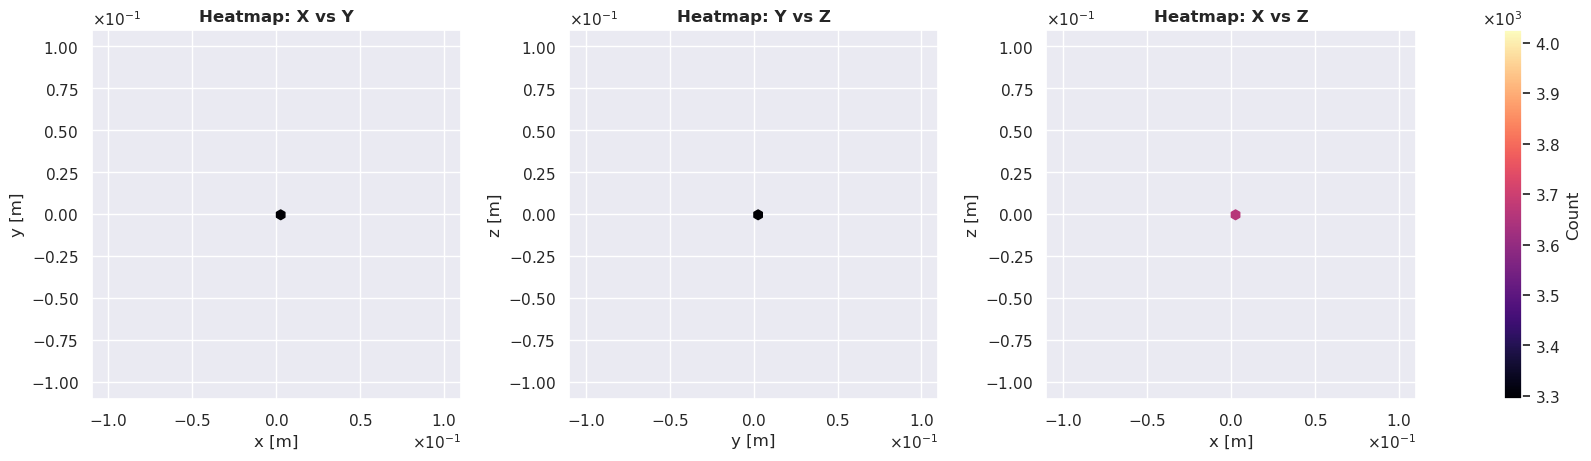

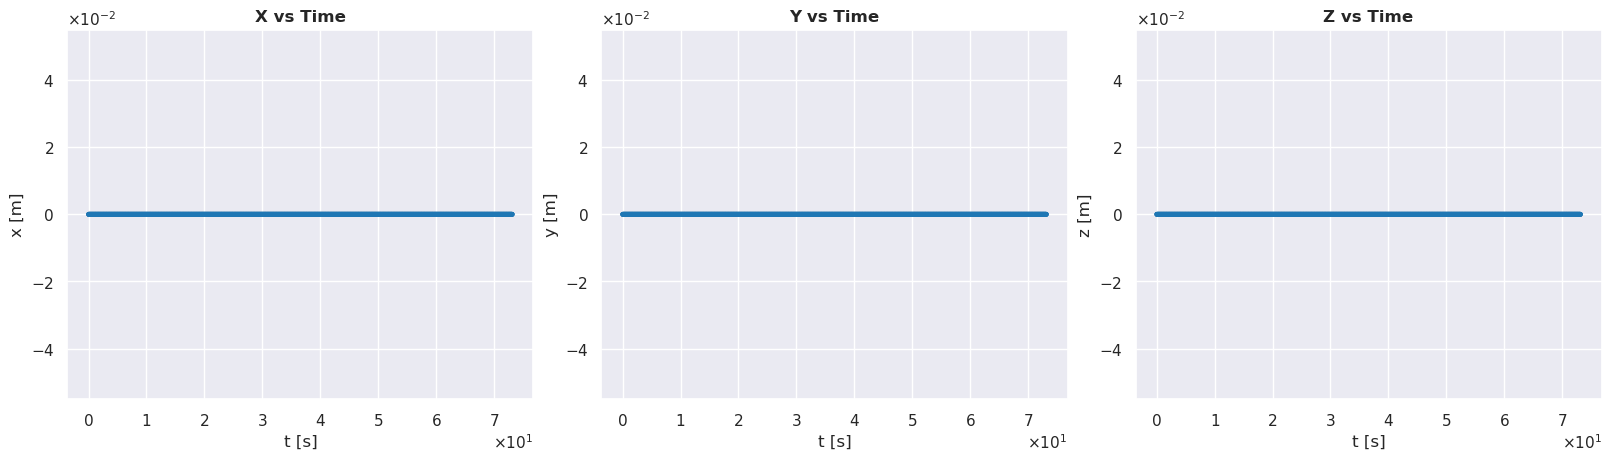

In [26]:
import seaborn as sns

import matplotlib.pyplot as plt

# Style
sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

# Build a continuous time axis in seconds (relative to start for readability)
t = resting_df["t_sec"] + resting_df["t_nsec"] * 1e-9
t_rel = t - t.iloc[0]

# Heatmaps: (x, y), (y, z), (x, z)
plot_heatmaps_xyz(resting_df)

# Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
plot_time_series_scatter_xyz(resting_df)


### Resting Drone with white noise

- Position: $\pm 0.02$
- Orientation: $\pm 0.01$
- Angular velocity: $\pm 0.01$
- Velocity: $\pm 0.01$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2}
\end{bmatrix}
$$


In [27]:
resting_df_white = pd.read_csv(
    "../tests/resting_ekf_white1/resting_ekf_white1.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df_white.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762423878  314417562 -0.001708 -0.000035  0.000872  0.000376  0.000918   
1  1762423878  355122355 -0.000385 -0.000431  0.000843  0.000156  0.000753   
2  1762423878  395758810 -0.000336 -0.000501  0.001174  0.000160  0.000763   
3  1762423878  436590993 -0.000277 -0.000216  0.000946  0.000164  0.000773   
4  1762423878  477336292 -0.000271 -0.000466  0.000684  0.000168  0.000783   

         zq         w  
0 -0.000107  1.000000  
1  0.000577  1.000000  
2  0.000634  0.999999  
3  0.000692  0.999999  
4  0.000750  0.999999  


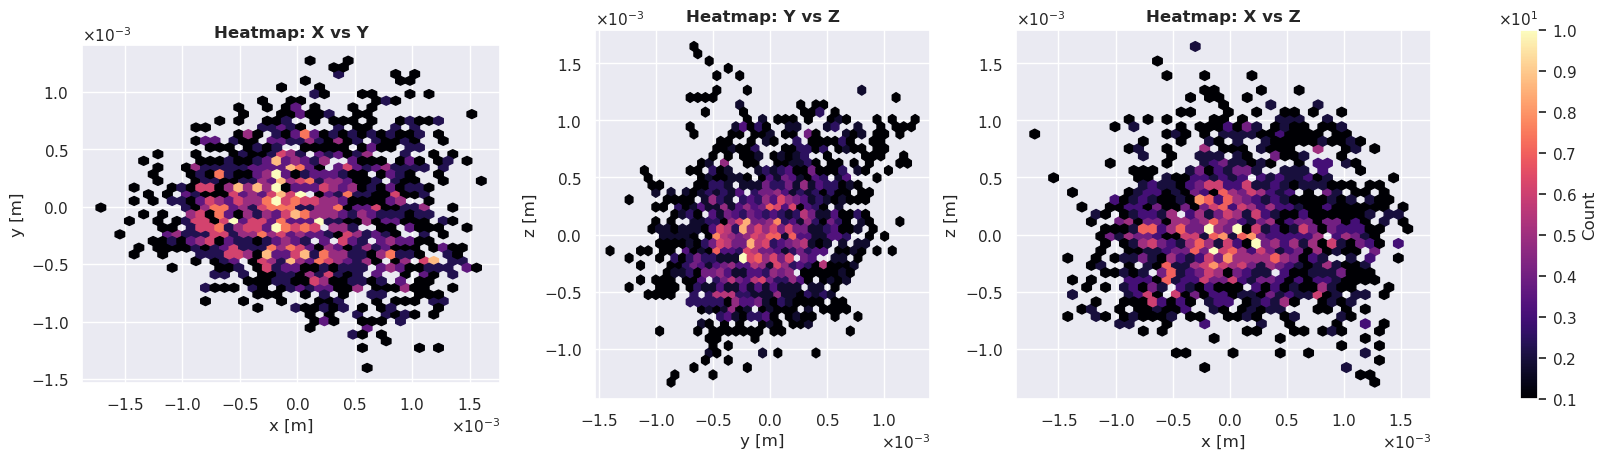

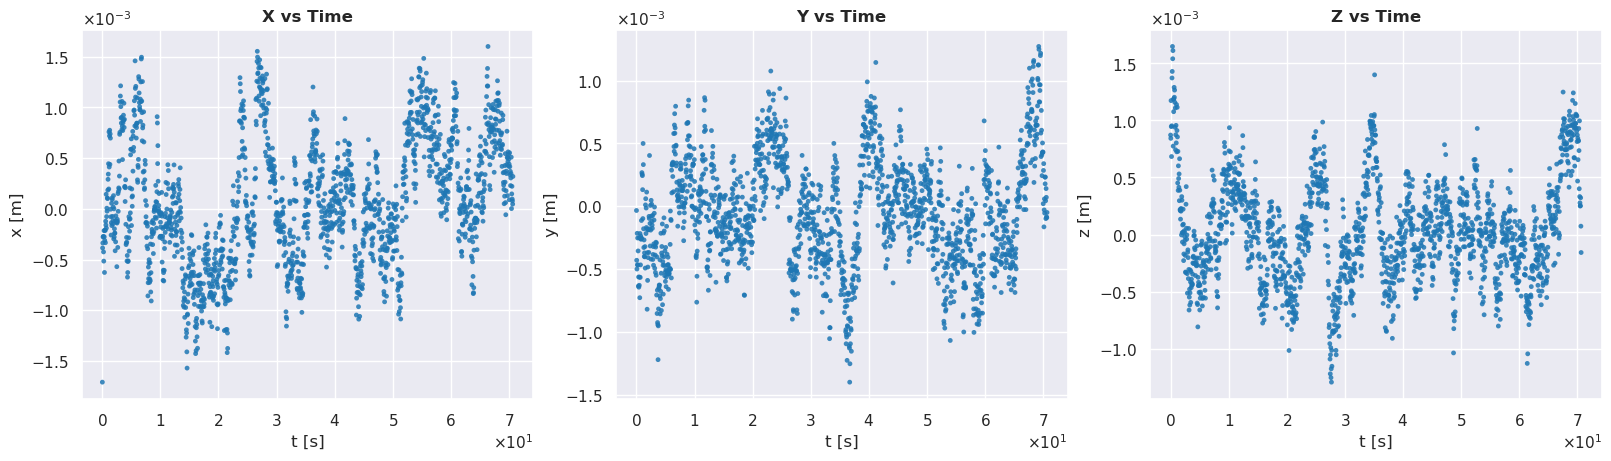

In [28]:
plot_heatmaps_xyz(resting_df_white)
plot_time_series_scatter_xyz(resting_df_white)


In [36]:
std_white = resting_df_white[["x", "y", "z"]].std()
print("Standard Deviation of Position (m) with Agilicious Noise and Agilicious Q:")
print(std_white)
avg_std_white = std_white.mean()
print(f"Average Standard Deviation: {avg_std_white} m")

Standard Deviation of Position (m) with Agilicious Noise and Agilicious Q:
x    0.000604
y    0.000428
z    0.000447
dtype: float64
Average Standard Deviation: 0.0004928853436660377 m


### Resting drone with standard Q and agilicious noise

Notes:
- Error values are from mock_vio.yaml in the agilicious repo
- Vision error is set to the same value!

Values:
- Position: $\pm 0.01$
- Orientation: $\pm 0.001$
- Angular velocity: $\pm 0.1$
- Velocity: $\pm 0.01$
$$
\mathbf{Q}=
\begin{bmatrix}
5.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 5.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 6.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 3.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 3.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 6.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 2.5\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 2.5\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 4.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 2.0\times10^{-2} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.5\times10^{-2}
\end{bmatrix}
$$

In [31]:
resting_df_white_default = pd.read_csv(
    "../tests/resting_ekf_white_default/resting_ekf_white_default.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w", "pose_cov_0", "pose_cov_7", "pose_cov_14",
    "pose_cov_21", "pose_cov_28", "pose_cov_35",]
)

print(resting_df_white_default.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762522997  827811760  0.001492  0.006509  0.000230 -0.000414 -0.000378   
1  1762522997  868441247  0.001567  0.004320  0.002136 -0.000482 -0.000664   
2  1762522997  909277484  0.003651  0.004932  0.000812 -0.000491 -0.000676   
3  1762522997  950075628  0.001843  0.001917  0.001948 -0.000500 -0.000687   
4  1762522997  990692823 -0.000565  0.004242  0.003374 -0.000508 -0.000697   

         zq         w  pose_cov_0  pose_cov_7  pose_cov_14  pose_cov_21  \
0  0.001179  0.999999    0.016817    0.020637     0.026666     0.025622   
1  0.000562  1.000000    0.008852    0.012672     0.017110     0.017762   
2  0.000574  0.999999    0.010898    0.014718     0.019566     0.019677   
3  0.000587  0.999999    0.012929    0.016749     0.022000     0.021660   
4  0.000600  0.999999    0.014960    0.018780     0.024438     0.023711   

   pose_cov_28  pose_cov_35  
0     0.028581     0.044754  
1     0.020401     0

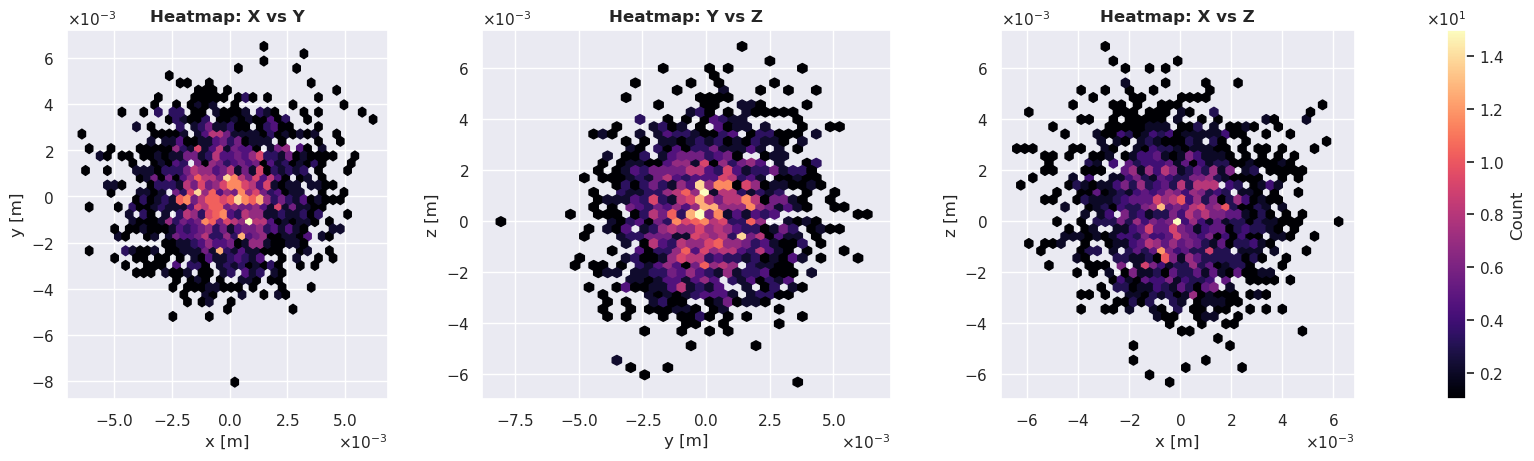

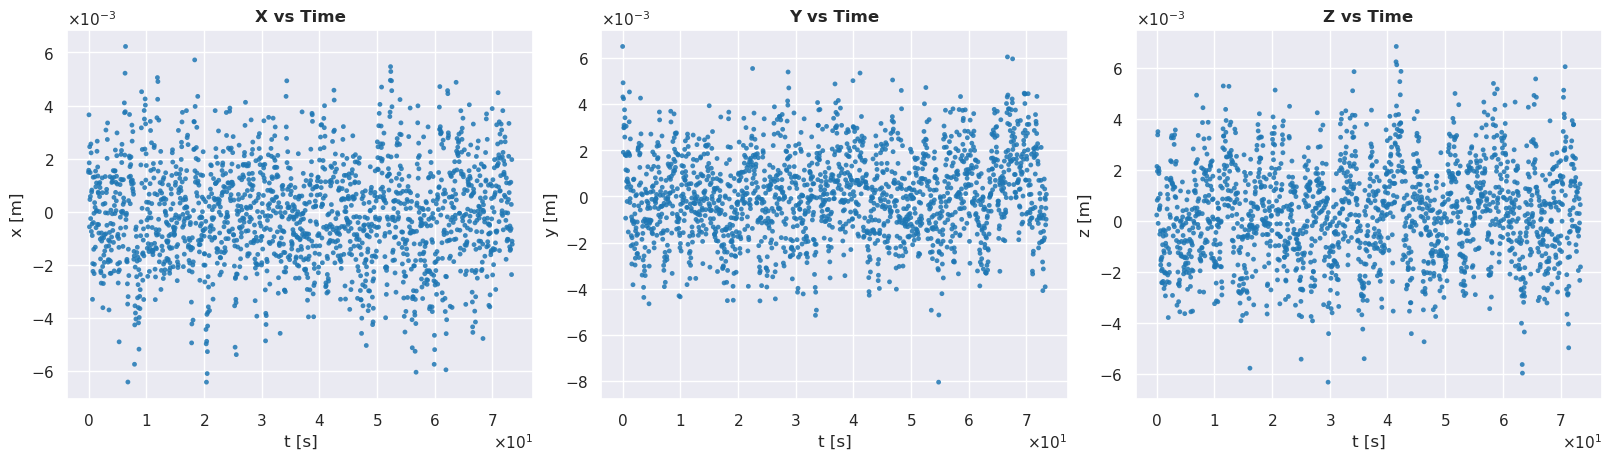

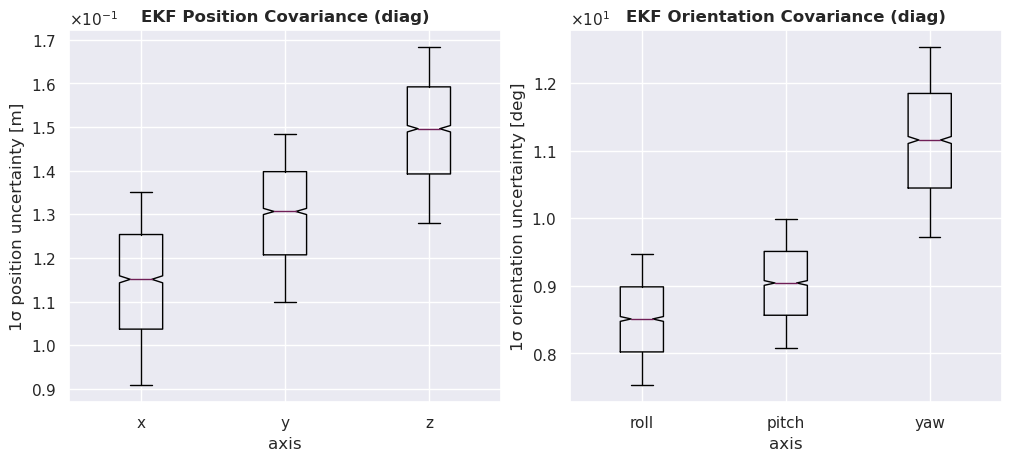

In [39]:
plot_heatmaps_xyz(resting_df_white_default)
plot_time_series_scatter_xyz(resting_df_white_default)
plot_state_covariance_boxplot(resting_df_white_default)

In [33]:
std_default = resting_df_white_default[["x", "y", "z"]].std()
print("Standard Deviation of Position (m) with Default Q and Agilicious Noise:")
print(std_default)

avg_std_default = std_default.mean()
print(f"Average Standard Deviation: {avg_std_default} m")

Standard Deviation of Position (m) with Default Q and Agilicious Noise:
x    0.001943
y    0.001885
z    0.001954
dtype: float64
Average Standard Deviation: 0.0019272039600456766 m


### Resting drone with agilicious noise

Note: Covariance matrix is from ekf_full_no_imu.yaml

- Position: $\pm 0.01$
- Orientation: $\pm 0.001$
- Angular velocity: $\pm 0.1$
- Velocity: $\pm 0.01$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3}
\end{bmatrix}
$$


In [33]:
resting_df_white_agi = pd.read_csv(
    "../tests/resting_ekf_white_agi/resting_ekf_white_agi.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w", "pose_cov_0", "pose_cov_7", "pose_cov_14",
    "pose_cov_21", "pose_cov_28", "pose_cov_35"]
)

resting_df_white_agi = add_rpy_from_quat(resting_df_white_agi)
print(resting_df_white_agi.head())

cov_z = resting_df_white_agi["pose_cov_14"].to_numpy()
std_z = np.sqrt(cov_z)
print("Mean EKF Estimated Standard Deviation in Z (m) with Agilicious Q:")
print(np.mean(std_z))

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762426913  592435028 -0.001588 -0.000135  0.005304 -0.004956  0.001887   
1  1762426913  633094499  0.002198 -0.001404  0.004544 -0.005761  0.002202   
2  1762426913  673711699 -0.000769  0.000039 -0.000971  0.003267  0.000355   
3  1762426913  714251275 -0.004424 -0.004263 -0.001351  0.004280  0.000269   
4  1762426913  754835263 -0.002863 -0.001463  0.004265  0.005209  0.000199   

         zq         w  pose_cov_0  pose_cov_7  pose_cov_14  pose_cov_21  \
0  0.000755  0.999986    0.015963    0.017846     0.019560     4.029518   
1  0.000845  0.999981    0.016867    0.018701     0.020398     6.845886   
2  0.000140  0.999995    0.016554    0.019146     0.021027     0.504996   
3  0.000082  0.999991    0.020147    0.022151     0.023785     1.051509   
4  0.000034  0.999986    0.015662    0.017480     0.019040     2.120679   

   pose_cov_28  pose_cov_35  roll_deg  pitch_deg   yaw_deg  
0     4.094158     

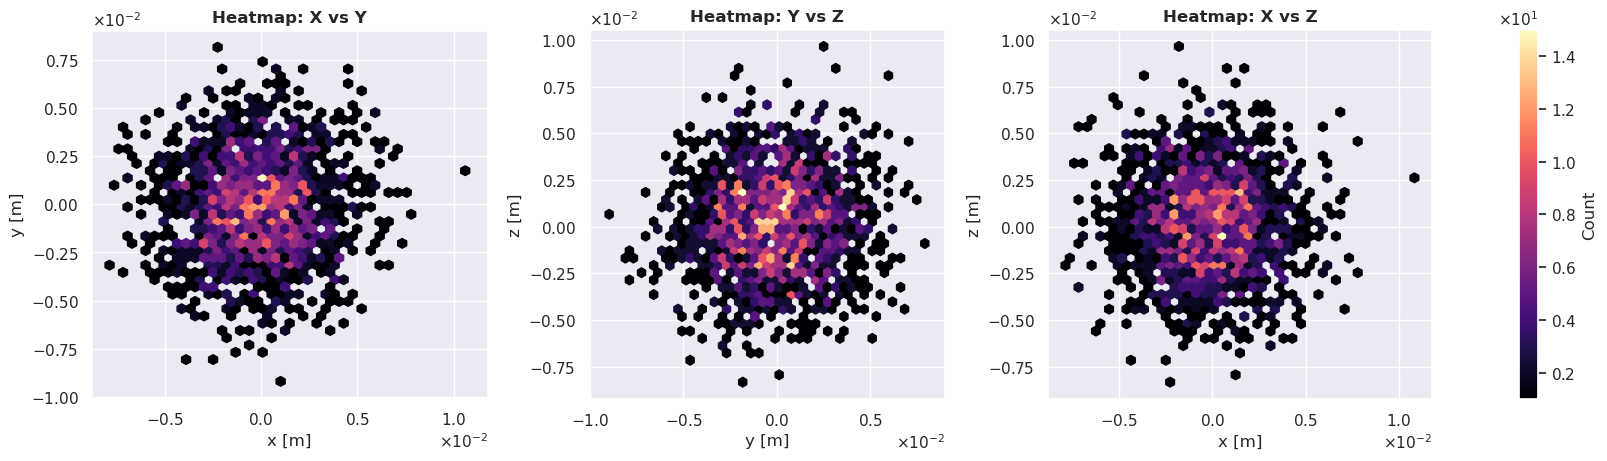

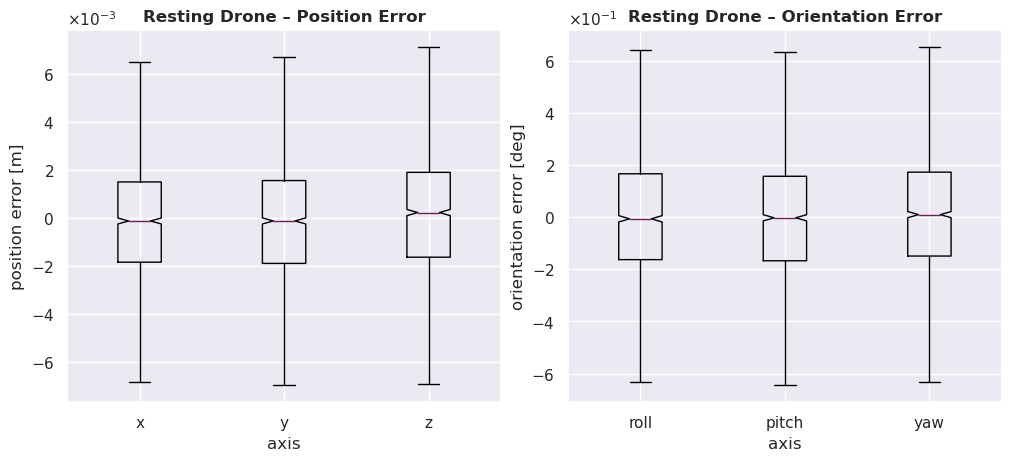

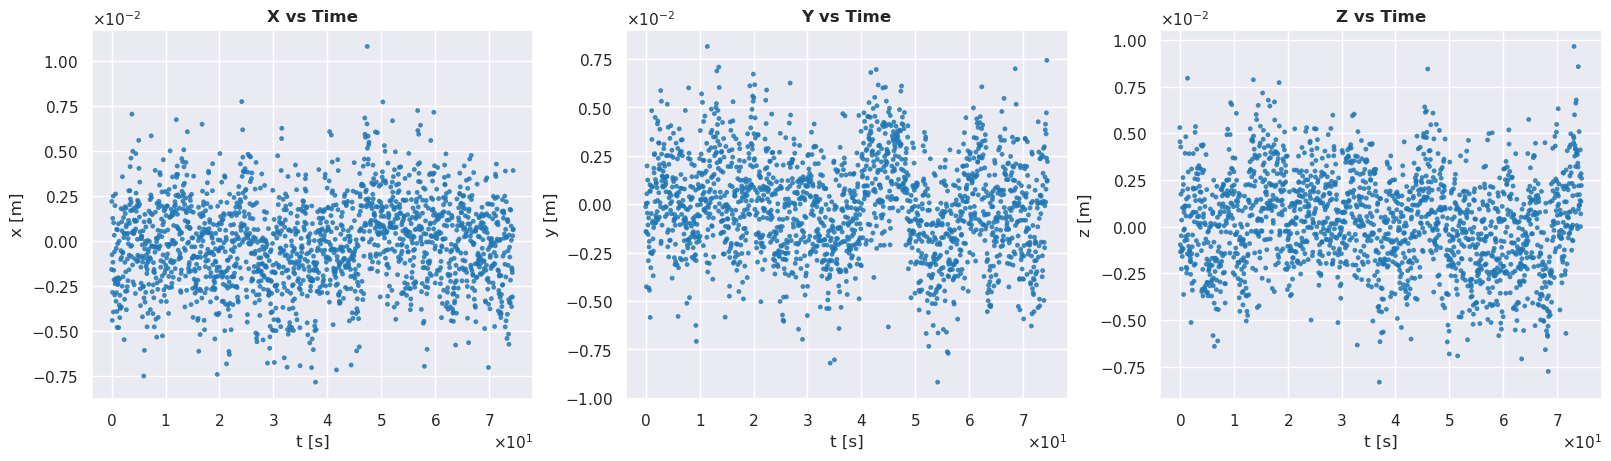

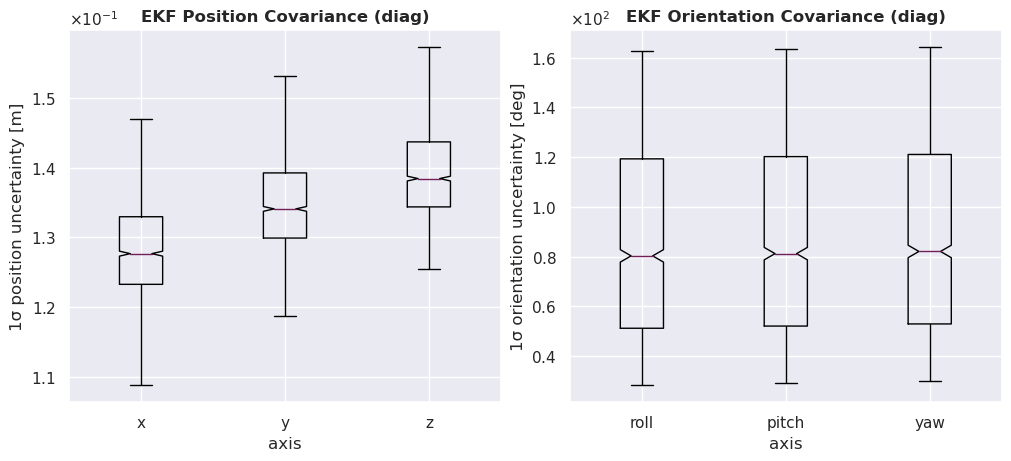

In [40]:
plot_heatmaps_xyz(resting_df_white_agi)
plot_orientation_error_boxplot(resting_df_white_agi)
plot_time_series_scatter_xyz(resting_df_white_agi)
plot_state_covariance_boxplot(resting_df_white_agi)

In [41]:
std_agi = resting_df_white_agi[["x", "y", "z"]].std()
print("Standard Deviation of Position (m) with Agilicious Noise and Agilicious Q:")
print(std_agi)

avg_std_agi = std_agi.mean()
print(f"Average Standard Deviation: {avg_std_agi} m")

Standard Deviation of Position (m) with Agilicious Noise and Agilicious Q:
x    0.002483
y    0.002555
z    0.002580
dtype: float64
Average Standard Deviation: 0.002539472432115297 m


## Resting drone with agilicious noise -- Added orientation updates

In [76]:
rest_agi_orientation = pd.read_csv("../tests/rest_agiqp/rest_agiqp.csv", 
                                    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w", 
                                             "pose_cov_0", "pose_cov_7", "pose_cov_14", "pose_cov_21", 
                                             "pose_cov_28", "pose_cov_35"]
)

print(rest_agi_orientation.head())

rest_agi_orientation = add_rpy_from_quat(rest_agi_orientation)

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1763205329  731296179 -0.002643 -0.002055  0.001486 -0.005058  0.003495   
1  1763205329  771906247  0.007484  0.013004 -0.002335  0.006439 -0.010704   
2  1763205329  812581176  0.002048 -0.000674 -0.001996  0.009732 -0.007703   
3  1763205329  853458135 -0.008425 -0.002718  0.007609 -0.004674 -0.006162   
4  1763205329  894134287  0.006743 -0.004723 -0.010314  0.000560 -0.002116   

         zq         w  pose_cov_0  pose_cov_7  pose_cov_14  pose_cov_21  \
0  0.001659  0.999980    0.010691    0.010691     0.010691     0.006270   
1  0.002392  0.999919    0.010225    0.010225     0.010226     0.005504   
2  0.011626  0.999855    0.010888    0.010888     0.010888     0.006916   
3  0.013846  0.999874    0.010566    0.010566     0.010566     0.004186   
4  0.000564  0.999997    0.011172    0.011172     0.011172     0.006524   

   pose_cov_28  pose_cov_35  
0     0.006271     0.006271  
1     0.005503     0

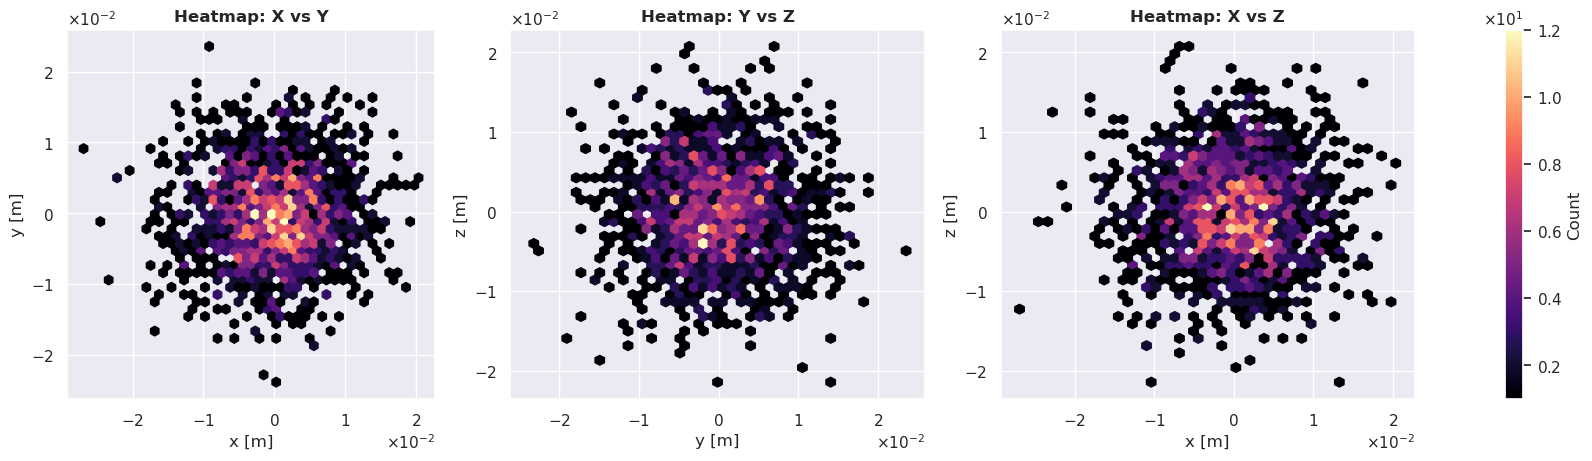

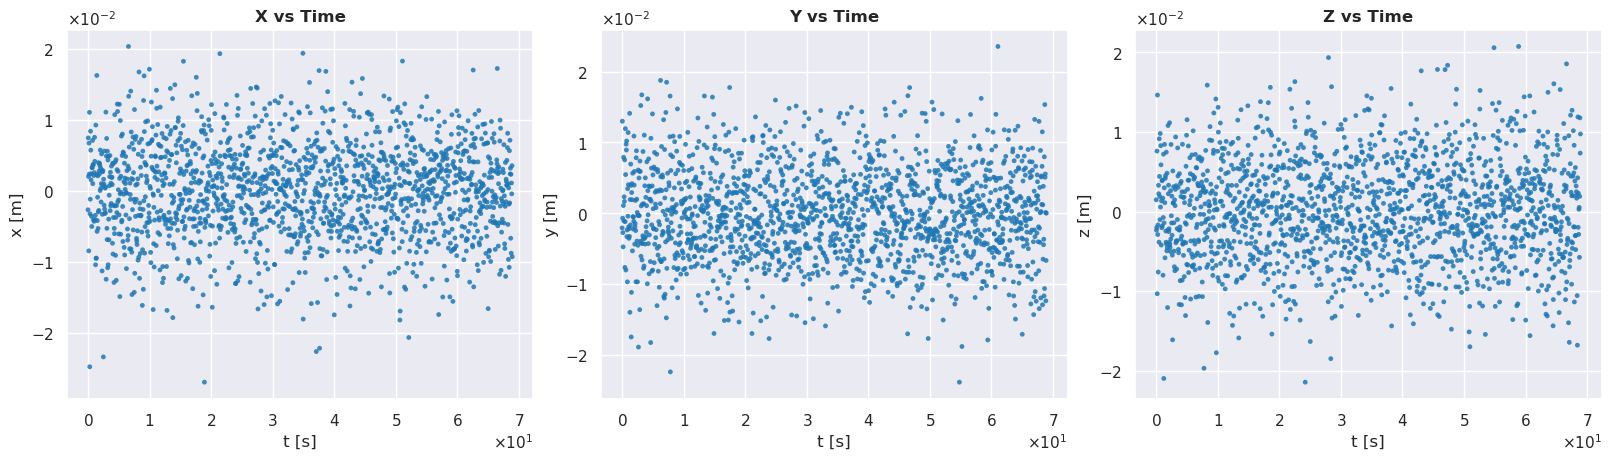

In [79]:
# plot_state_covariance_boxplot(rest_agi_orientation)
# plot_orientation_error_boxplot(rest_agi_orientation)
# plot_time_series_covariance_rpy(rest_agi_orientation)
plot_heatmaps_xyz(rest_agi_orientation)
plot_time_series_scatter_xyz(rest_agi_orientation)

### Constant velocity drone default

v = 0.5 m/s; Default covariances

Values of VIO:
- Position: $\pm 0.01$
- Orientation: $\pm 0.001$
- Angular velocity: $\pm 0.1$
- Velocity: $\pm 0.01$

Values of Vision:
- Position: $\pm 0.002$
- Orientation: $\pm 0.001$
$$
\mathbf{Q}=
\begin{bmatrix}
5.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 5.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 6.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 3.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 3.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 6.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 2.5\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 2.5\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 4.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 2.0\times10^{-2} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.5\times10^{-2}
\end{bmatrix}
$$

In [ ]:
constant_v_ekf_default_df = pd.read_csv(
    "../tests/constant_v_ekf_default/constant_v_ekf_default.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w", ]
)

print(constant_v_ekf_default_df.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762610577  981756956  2.154745 -0.001062  0.000061  0.000248 -0.000689   
1  1762610578   22736203  2.176309 -0.001511 -0.000606  0.000249 -0.000704   
2  1762610578   63613742  2.195366 -0.001633 -0.001478  0.000250 -0.000718   
3  1762610578  104884805  2.218036 -0.003166  0.001190  0.000655 -0.000512   
4  1762610578  145850679  2.238649 -0.003088  0.000099  0.000663 -0.000539   

         zq         w  
0 -0.000619  1.000000  
1 -0.000623  1.000000  
2 -0.000628  1.000000  
3 -0.000505  1.000000  
4 -0.000520  0.999999  


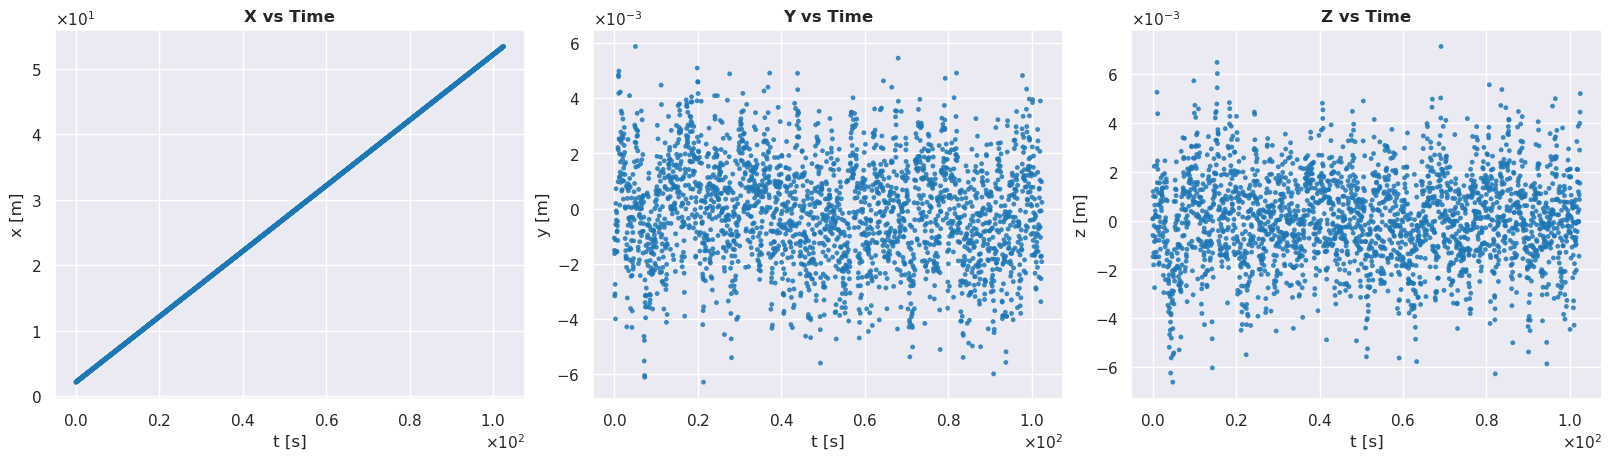

In [75]:
#plot_heatmaps_xyz(constant_v_ekf_df)
plot_time_series_scatter_xyz(constant_v_ekf_default_df)

In [76]:
const_v_clean_default = constant_v_ekf_default_df.copy()

t_rel = find_t_rel(const_v_clean_default)

# Either set known velocity:
v_est = 0.5
# Or estimate from data (linear fit):
# v_est = np.polyfit(t_rel, const_v_clean_default["x"], 1)[0]
const_v_clean_default = subtract_velocity_trend(const_v_clean_default, v_est)

print("Estimated velocity (m/s):", v_est)
print(const_v_clean_default[["x_detrended"]].head())

std_v_clean = const_v_clean_default["x_detrended"].std()
print("Std of detrended x (m):", std_v_clean)

Estimated velocity (m/s): 0.5
   x_detrended
0     2.154745
1     2.155819
2     2.154437
3     2.156472
4     2.156602
Std of detrended x (m): 0.001897497338729531


### Constant velocity with agi covariances

v = 0.5 m/s

Values of VIO:
- Position: $\pm 0.01$
- Orientation: $\pm 0.001$
- Angular velocity: $\pm 0.1$
- Velocity: $\pm 0.01$

Values of Vision:
- Position: $\pm 0.002$
- Orientation: $\pm 0.001$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3}
\end{bmatrix}
$$

In [52]:
constant_v_ekf_agi_df = pd.read_csv(
    "../tests/constant_v_ekf_agi/constant_v_ekf_agi.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(constant_v_ekf_agi_df.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762609230  852622049  2.589302 -0.002761  0.001943 -0.000334  0.001557   
1  1762609230  893854035  2.606012 -0.001930  0.001746 -0.000377  0.001908   
2  1762609230  935060138  2.629475  0.000076  0.002004 -0.000892  0.001058   
3  1762609230  976991014  2.647738  0.001842  0.004932 -0.001024  0.001314   
4  1762609231   18151515  2.666601 -0.000416  0.002904 -0.001151  0.001656   

         zq         w  
0 -0.001024  0.999998  
1 -0.000928  0.999998  
2  0.000336  0.999999  
3  0.000908  0.999998  
4  0.001334  0.999997  


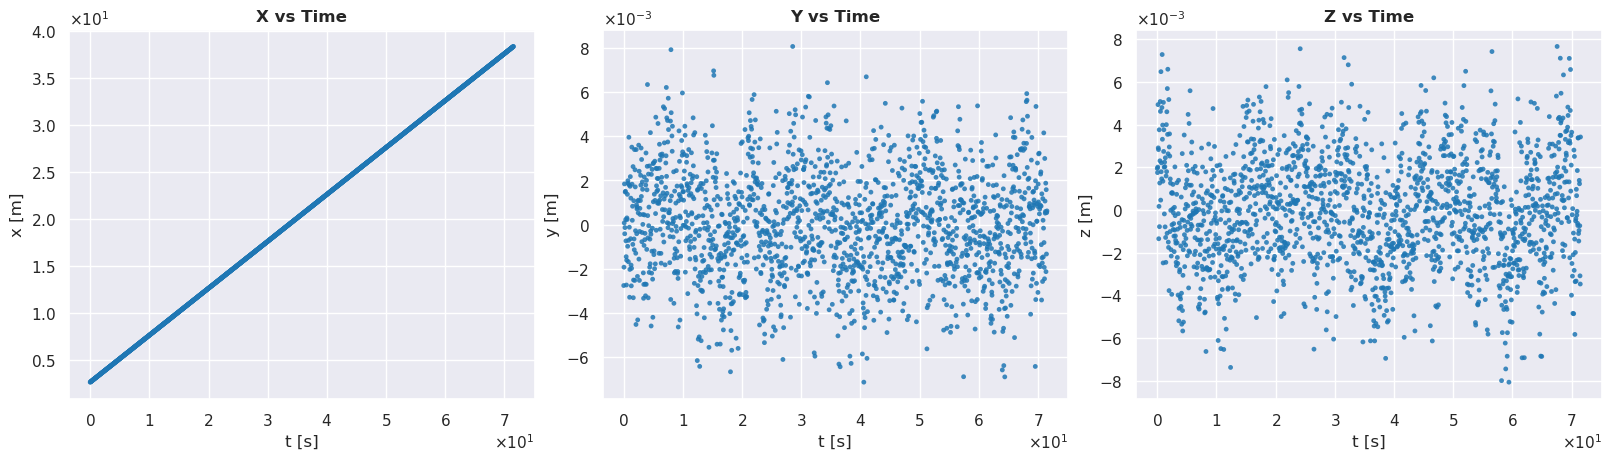

In [54]:
plot_time_series_scatter_xyz(constant_v_ekf_agi_df)

In [65]:
const_v_agi_clean = constant_v_ekf_agi_df.copy()

t_rel = find_t_rel(const_v_agi_clean)

# Either set known velocity:
v_est = 0.5
# Or estimate from data (linear fit):
# v_est = np.polyfit(t_rel, const_v_agi_clean["x"], 1)[0]

const_v_agi_clean = subtract_velocity_trend(const_v_agi_clean, v_est)

print("Estimated velocity (m/s):", v_est)
print(const_v_agi_clean[["x_detrended"]].head())

std_v_clean = const_v_agi_clean["x_detrended"].std()
print("Std of detrended x (m):", std_v_clean)

Estimated velocity (m/s): 0.5
   x_detrended
0     2.589302
1     2.585396
2     2.588256
3     2.585554
4     2.583836
Std of detrended x (m): 0.002457697798728624
